# Machine Learning-Based Prediction of Q-Factor from Optical Microring Resonator Geometry

## Introduction

This project investigates the use of machine learning
to predict the quality factor (Q-factor) of optical
microresonators using its geomtrical features.

The objective is to explore the dataset, preprocess
its features, train regression models, and evaluate
their predictive performance.

### Dataset Source

This project uses a synthetic dataset of all-pass optical
micro-ring resonators originally developed by
Valencia-Garzon et al. [1].

The dataset was generated using numerical simulations
to investigate relationships between resonator geometry
and optical performance.

**References**

[1] S. Valencia-Garzon et al.,
"Synthetic Dataset for Analyzing Geometry-Dependent
Optical Properties of All-Pass Micro-Ring Resonators,"
*Data*, vol. 10, no. 1, art. 3, 2025.
https://doi.org/10.3390/data10010003

[2] R. Paschotta, "Q-factor," *RP Photonics Encyclopedia*. Accessed: Nov. 4, 2026. [Online]. Available: https://www.rp-photonics.com/q_factor.html

### Library Imports

In [222]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("Microresonator ML environment ready!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Microresonator ML environment ready!
NumPy: 2.4.6
Pandas: 3.1.0
Scikit-learn: 1.9.1


In [223]:
df = pd.read_csv("data/Data set Microresonator Optical.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (4718, 15)


,w [um],h [um],R [um],GAP [um],FSR [nm],FWHM [nm],Q FACTOR,LOSS,FINESSE,k,t,MAX TRANSMITTANCE,MIN TRANSMITTANCE,EFFECTIVE INDEX,% TRANSMITTANCE
0,1.0,0.18,40.0,0.5,6.40935,3.073140,504.708109,0.043525,2.085603,0.741274,0.089850,0.578010,0.519857,1.493476,0.058152
1,1.0,0.18,40.0,0.6,6.40935,3.064473,506.135523,0.043525,2.091502,0.790169,0.054119,0.649596,0.597896,1.493476,0.051700
2,1.0,0.18,40.0,0.7,6.40935,3.059536,506.952297,0.043525,2.094877,0.817994,0.032338,0.692059,0.644906,1.493476,0.047153
3,1.0,0.18,40.0,0.8,6.40935,3.056374,507.476654,0.043525,2.097044,0.835634,0.019320,0.719622,0.675694,1.493476,0.043928
4,1.0,0.18,40.0,0.9,6.40935,3.054563,507.777617,0.043525,2.098287,0.845953,0.011536,0.735977,0.694061,1.493476,0.041916


In [224]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4718 entries, 0 to 4717
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   w [um]             4718 non-null   float64
 1   h [um]             4718 non-null   float64
 2   R [um]             4718 non-null   float64
 3   GAP [um]           4718 non-null   float64
 4   FSR [nm]           4718 non-null   float64
 5   FWHM [nm]          4718 non-null   float64
 6   Q FACTOR           4718 non-null   float64
 7   LOSS               4718 non-null   float64
 8   FINESSE            4718 non-null   float64
 9   k                  4718 non-null   float64
 10  t                  4718 non-null   float64
 11  MAX TRANSMITTANCE  4718 non-null   float64
 12  MIN TRANSMITTANCE  4718 non-null   float64
 13  EFFECTIVE INDEX    4718 non-null   float64
 14  % TRANSMITTANCE    4718 non-null   float64
dtypes: float64(15)
memory usage: 553.0 KB


In [225]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
w [um],4718.0,1.295549,0.222788,1.000000,1.000000,1.200000,1.400000,1.600000
h [um],4718.0,0.219407,0.027730,0.180000,0.200000,0.220000,0.240000,0.260000
R [um],4718.0,114.310089,49.557464,30.000000,70.000000,115.000000,155.000000,200.000000
GAP [um],4718.0,0.800000,0.200021,0.500000,0.600000,0.800000,1.000000,1.100000
FSR [nm],4718.0,2.814006,1.671500,1.207710,1.590400,2.187300,3.493490,8.487540
FWHM [nm],4718.0,0.151588,0.375026,0.007265,0.026520,0.051433,0.106436,3.846600
Q FACTOR,4718.0,41943.444701,37750.906094,403.774633,14556.374189,30151.077310,58445.196537,213296.217639
LOSS,4718.0,0.959268,0.124107,0.043525,0.980849,0.994258,0.998058,0.999793
FINESSE,4718.0,60.090317,48.951221,2.085603,22.356736,44.084309,85.659283,227.011466
k,4718.0,0.919736,0.074590,0.376243,0.899523,0.943804,0.968272,0.987431


In [226]:
df.duplicated().sum()

np.int64(0)

### What is Quality Factor?
Quality factor is the ratio between stored energy and energy dissipated per radian of oscillation. It is characterized as the measure of strength of the damping of its oscillations, for example if we have a high Q factor we will receive lower damping and lower energy loss relative to the stored energy. [2]


The quality factor for microring resonators is defined as:

$$
Q = \frac{\lambda_{\mathrm{res}}}{\mathrm{FWHM}}
$$

Rearranging:

$$
\lambda_{\mathrm{res}} = Q \cdot \mathrm{FWHM}
$$

Gives us the resonance wavelength.


Since Q-factor is the target variable, its distribution must be examined to understand its variability and identify the type of skewness

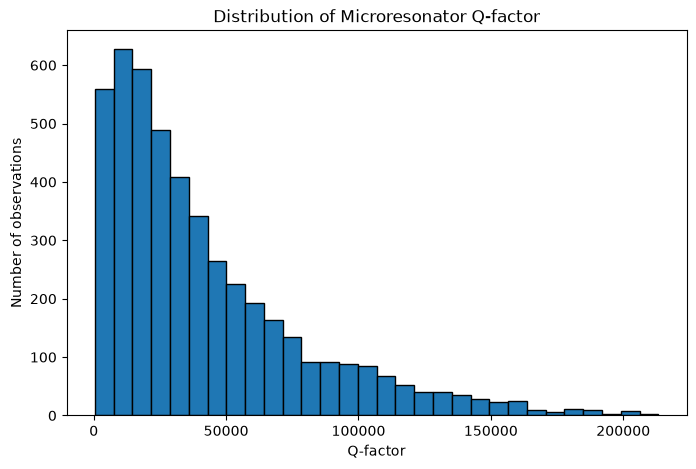

In [227]:
plt.figure(figsize=(8, 5))

plt.hist(df["Q FACTOR"], bins=30, edgecolor="black")

plt.xlabel("Q-factor")
plt.ylabel("Number of observations")
plt.title("Distribution of Microresonator Q-factor")

plt.show()

In [228]:
df["Q FACTOR"].skew()

np.float64(1.468498039876496)

In [229]:
ex = df["Q FACTOR"] > 150000
ex_mean = ex.mean()
print(f"Approximately {ex_mean:.2%} of resonators have Q-factors that exceed 150,000")

Approximately 1.93% of resonators have Q-factors that exceed 150,000


Using the resonance wavelength equation we find:

In [230]:
df.columns = df.columns.str.strip()

(df["Q FACTOR"] * df["FWHM [nm]"]).describe()

count    4718.000000
mean     1549.962056
std         0.907772
min      1546.515800
25%      1549.455680
50%      1549.987340
75%      1550.483560
max      1553.159360
dtype: float64

Although the resonance wavelength is related to the resonator's optical properties, it will not be used as a predictor because this project is focused on the geometry based Q-factor estimation. 

## Beginning of EDA

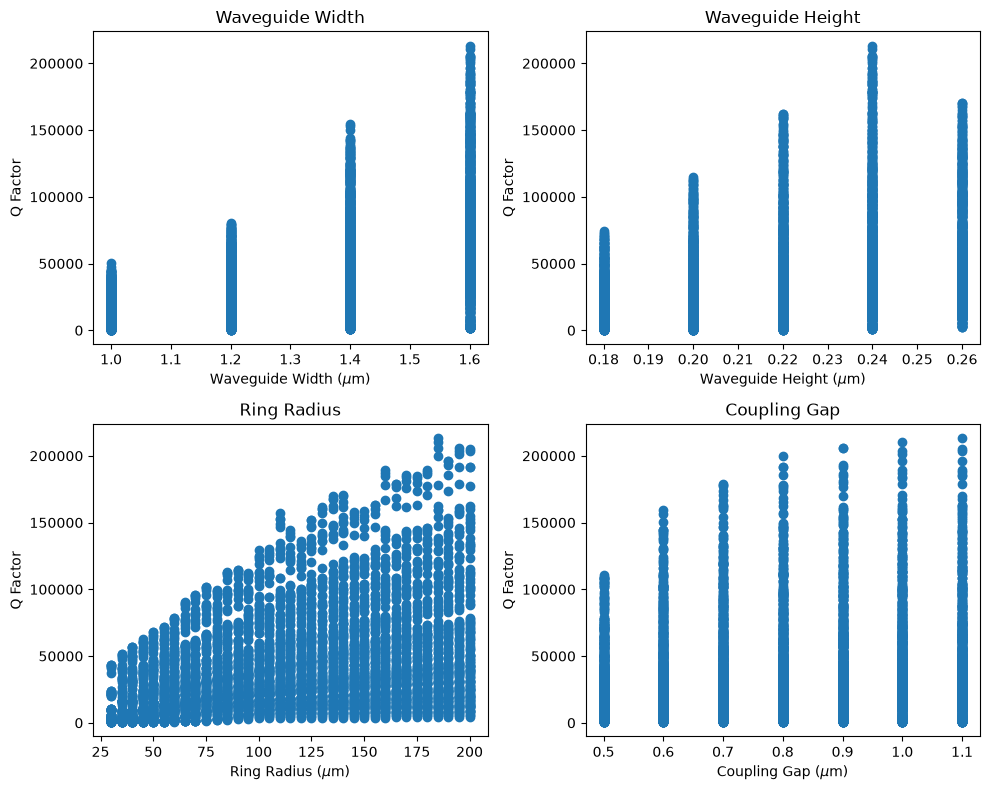

In [231]:
features = {'Waveguide Width' : df['w [um]'], 'Waveguide Height' : df['h [um]'], 'Ring Radius' : df['R [um]'], 'Coupling Gap' : df['GAP [um]']}
target = df['Q FACTOR']
fig, axs = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, column) in zip(axs.flat, features.items()):
    ax.scatter(column, target)
    ax.set_title(name)
    ax.set_xlabel(f"{name} ($\\mu$m)")
    ax.set_ylabel("Q Factor")
fig.tight_layout()
plt.show()

Ring radius appears to have the strongest correlation with Q factor let's explore that below:

In [232]:
radius = df['R [um]']
r_corr = radius.corr(target)
print(f'The correlation between radius and Q Factor is {r_corr:.3f}')

The correlation between radius and Q Factor is 0.382


Waveguide widths and heights had a stronger correlation than the radius, meaning my hypothesis was incorrect. Since the corrwith() method defaults to Pearson correlation which is associated with a linear association, it does not guarantee that a weaker coefficient is irrelevant to predicting the Q Factor.

In [233]:
geometric_df = pd.DataFrame(features)
geometric_df.corrwith(target)

Waveguide Width     0.624294
Waveguide Height    0.407844
Ring Radius         0.382264
Coupling Gap        0.187773
dtype: float64

In [234]:
X = geometric_df
y = df["Q FACTOR"]
X.columns

Index(['Waveguide Width', 'Waveguide Height', 'Ring Radius', 'Coupling Gap'],
      dtype='str')

In [235]:
X.duplicated().sum()

np.int64(0)

In [236]:
df.groupby("GAP [um]")["Q FACTOR"].agg(["count", "mean", "median", "max"]).round(2)

,count,mean,median,max
GAP [um],,,,
0.5,674,27025.46,18264.63,110581.62
0.6,674,35282.86,23705.36,159214.38
0.7,674,41211.99,29096.70,178654.60
0.8,674,45032.38,32877.25,200065.44
0.9,674,47278.10,34663.94,205485.51
1.0,674,48514.04,36211.94,210345.48
1.1,674,49259.29,36873.81,213296.22


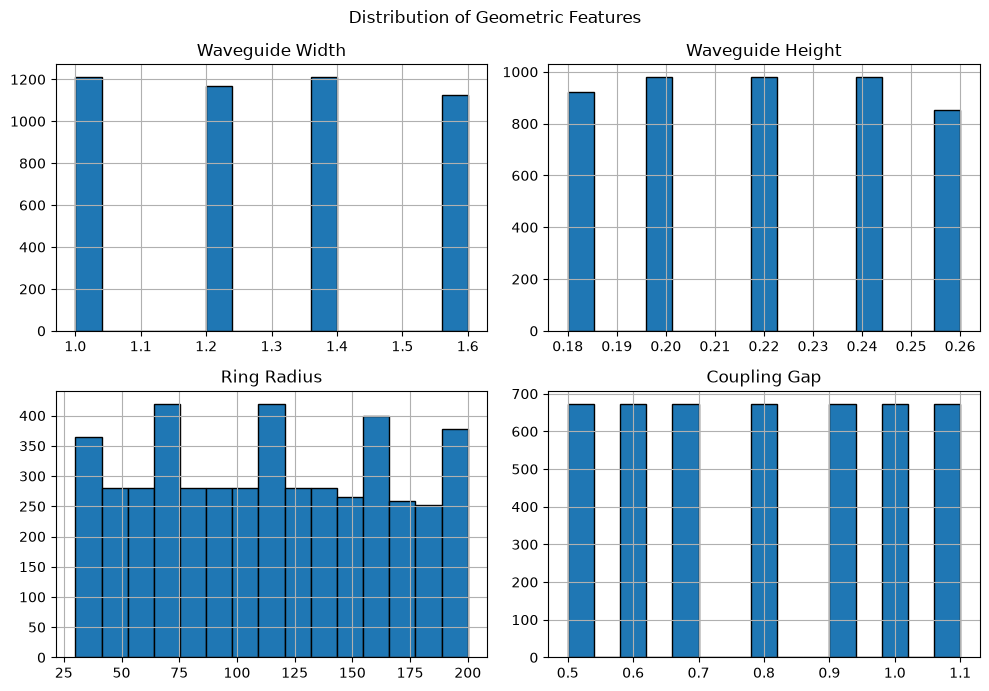

In [237]:
geometric_df.hist(bins=15, figsize=(10, 7), edgecolor="black")

plt.suptitle("Distribution of Geometric Features")
plt.tight_layout()
plt.show()

In [238]:
geometric_df.nunique()

Waveguide Width      4
Waveguide Height     6
Ring Radius         35
Coupling Gap         7
dtype: int64

In [239]:
geometric_df.duplicated().sum()

np.int64(0)

## Preprocessing

In [240]:

X = geometric_df.copy()
y = df["Q FACTOR"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (4718, 4)
Target shape: (4718,)


In [241]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 3774
Testing samples: 944


In [242]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

linear_model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Waveguide Width','Waveguide Height','Ring Radius','Coupling Gap']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [243]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R² Score: {r2:.4f}")


MAE: 12885.59
RMSE: 17044.60
R² Score: 0.7873


In [244]:
test_r2 = linear_model.score(X_test, y_test)
train_r2 = linear_model.score(X_train, y_train)
print(f"Test R²: {test_r2:.2f}")
print(f"Train R²: {train_r2:.2f}")

Test R²: 0.79
Train R²: 0.79


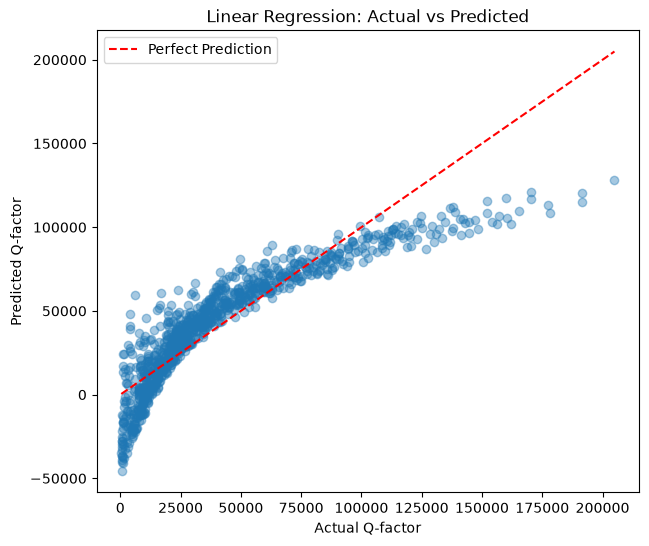

In [245]:

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", label="Perfect Prediction")

plt.xlabel("Actual Q-factor")
plt.ylabel("Predicted Q-factor")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.show()


In [246]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

In [247]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print(f"MAE: {mae_rf:.2f}")
print(f"RMSE: {rmse_rf:.2f}")
print(f"R² Score: {r2_rf:.2f}")

MAE: 835.68
RMSE: 1417.85
R² Score: 1.00


In [248]:
train_r2_rf = rf_model.score(X_train, y_train)
print(f"Train R²: {train_r2_rf:.2f}")

Train R²: 1.00


In [249]:
from sklearn.model_selection import GroupKFold, cross_val_score


group_cols = ["Waveguide Width", "Waveguide Height", "Ring Radius"]

groups_train = X_train.groupby(group_cols).ngroup()

print(groups_train.nunique())

674


In [250]:
group_cv = GroupKFold(n_splits=5)

cv_scores_rf = cross_val_score(estimator=rf_model, X=X_train, y=y_train, cv=group_cv, groups=groups_train, scoring="r2")
print(cv_scores_rf.mean())
print(cv_scores_rf.std())

0.9913044758043673
0.0016704775908795168


In [251]:
cv_scores_lr = cross_val_score(estimator=linear_model, X=X_train, y=y_train, cv=group_cv, groups=groups_train, scoring="r2")
print(cv_scores_lr.mean())
print(cv_scores_lr.std())

0.7906155115056188
0.011458681983653782
